PLOTS RAW MATCHING RESULTS

--- Anchor Match Quality Analysis ---
Number of anchors with at least one match with WMD < 0.5: 35
Number of anchors with at least one match with WMD < 0.6: 51
Number of anchors with at least one match with WMD < 0.7: 66
Number of anchors with at least one match with WMD < 0.8: 72
Number of anchors with at least one match with WMD < 0.9: 83
Number of anchors with at least one match with WMD < 1.0: 96


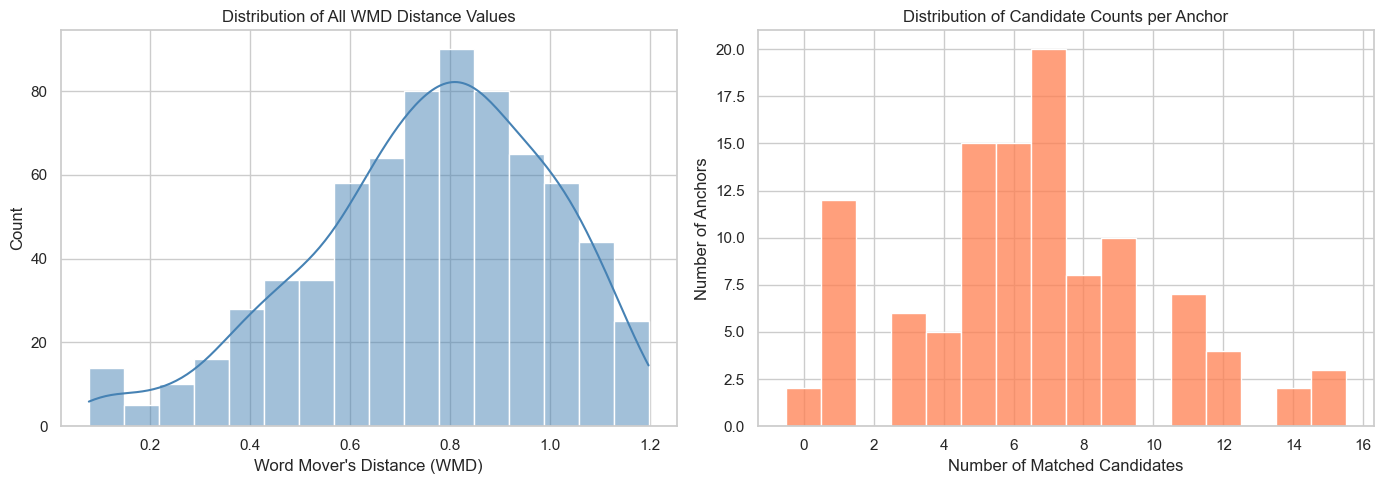

In [7]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Load matching data from json file
with open("../data/raw/matching_dict_raw.json", "r") as f:
    matching_data = json.load(f)

# Initialize lists to store metrics
all_distances = []
match_counts = []
min_distances_per_anchor = []

# Parse dictionary to extract distances and counts
for anchor, candidates in matching_data.items():
    counts = len(candidates)
    match_counts.append(counts)
    if counts > 0:
        distances = list(candidates.values())
        all_distances.extend(distances)
        min_distances_per_anchor.append(min(distances))

# Print threshold analysis for anchors
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
print("--- Anchor Match Quality Analysis ---")
for t in thresholds:
    count = sum(1 for d in min_distances_per_anchor if d < t)
    print(f"Number of anchors with at least one match with WMD < {t}: {count}")

# Set up seaborn style for visualization
sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot distribution of all WMD values
sns.histplot(all_distances, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of All WMD Distance Values")
axes[0].set_xlabel("Word Mover's Distance (WMD)")
axes[0].set_ylabel("Count")

# Plot distribution of matched candidate counts per anchor
sns.histplot(match_counts, kde=False, discrete=True, ax=axes[1], color="coral")
axes[1].set_title("Distribution of Candidate Counts per Anchor")
axes[1].set_xlabel("Number of Matched Candidates")
axes[1].set_ylabel("Number of Anchors")

# Adjust layout and show plots
plt.tight_layout()
plt.show()

PLOT OPTIMIZED MATCHING RESULTS

--- Optimized Anchor Match Quality Analysis ---
Number of anchors with an optimized match with WMD < 0.5: 25
Number of anchors with an optimized match with WMD < 0.6: 42
Number of anchors with an optimized match with WMD < 0.7: 59
Number of anchors with an optimized match with WMD < 0.8: 67
Number of anchors with an optimized match with WMD < 0.9: 77
Number of anchors with an optimized match with WMD < 1.0: 90


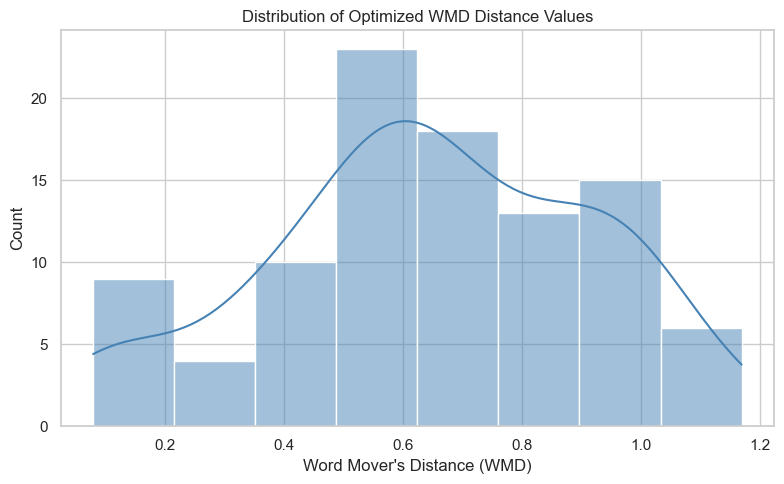

In [8]:
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Carica i dati di matching ottimizzati dal file json
with open("../data/interim/matching_dict_optimized.json", "r") as f:
    optimized_data = json.load(f)

# Inizializza la lista per memorizzare le distanze
all_distances = []

# Esplora il dizionario ottimizzato per estrarre i WMD
for anchor, info in optimized_data.items():
    dist = info["wmd"]
    all_distances.append(dist)

# Stampa l'analisi delle soglie per gli anchor ottimizzati
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
print("--- Optimized Anchor Match Quality Analysis ---")
for t in thresholds:
    count = sum(1 for d in all_distances if d < t)
    print(f"Number of anchors with an optimized match with WMD < {t}: {count}")

# Imposta lo stile di seaborn per la visualizzazione
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(8, 5))

# Plot della distribuzione dei valori WMD ottimizzati
sns.histplot(all_distances, kde=True, color="steelblue")
plt.title("Distribution of Optimized WMD Distance Values")
plt.xlabel("Word Mover's Distance (WMD)")
plt.ylabel("Count")

# Regola il layout e mostra il grafico
plt.tight_layout()
plt.show()